# A16 whole-system backtest: would the card have warned?

PRD R33 and the "Whole system" row of `docs/model-evaluation.md`. For every LGA-year from 2000 to 2024, the card's season warning is rebuilt as the engine would have shown it for that year's season type, from the **other** years only (leave one year out), and compared with what happened.

- **Warning:** the crop fits the rainy season in under 8 of 10 years of that type (`engine.water.risk_fit_share`): the card shows a risk line or drops the crop.
- **Outcome 1, season fit:** the crop did not finish inside that year's rains (A9 on that year's CHIRPS rain). Partly circular: a year's type is built from its own onset and season length, so this tests that the card carries the type's risk, not that the type can be forecast. In use, the advisor picks the type from the NiMet seasonal forecast.
- **Outcome 2, crop stress:** observed cropland greenness was stressed that year (MODIS, independent of the weather inputs).
- **Baseline:** the same warning with no season type, from all other years.

The PRD asks for a documented bad season "from records". No such record is in the repo, so the bad years tested are the four worst in the MODIS greenness record (from A5). Formulas: `model/backtest.py`.

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import backtest as bt
from model import experiments
from model.experiments import log_experiments
from model.io import write_csv, write_json
from model.settings import load_model_config

## 1. Rebuild the warning for every LGA-year, leaving that year out

In [4]:
# Per crop and LGA-year (A9, 2000 to 2024 where A5 gives a type): the leave-one-year-out fit
# share with and without the season type, and whether each would have warned. Greenness stress
# per LGA-year comes from A5's table. Scope: all 23 LGAs (21 for greenness: Kaduna North and
# South have too little cropland).
cfg = load_model_config()
out = cfg.paths.output_dir
rows = pd.read_csv(out / "a9" / "a9_lga_year_crop.csv")
types = pd.read_csv(out / "a5" / "a5_lga_year_types.csv")[
    ["lga", "year", "stressed", "low_cropland"]
]
table = bt.backtest_table(rows, cfg.engine.water.risk_fit_share).merge(
    types, on=["lga", "year"], how="left"
)
crops = ["maize", "sorghum", "millet", "groundnut", "soybean", "cowpea"]
table = table[table["crop"].isin(crops)]
{"LGA-years per crop": int(table.groupby("crop").size().iloc[0]), "crops": crops}

{'LGA-years per crop': 575,
 'crops': ['maize', 'sorghum', 'millet', 'groundnut', 'soybean', 'cowpea']}

## 2. Season fit: does the card warn in the years the crop failed to finish?

In [5]:
# Hit rate, false-alarm rate and lift, with the season type and without (baseline).
rates = []
for crop, g in table.groupby("crop"):
    for scheme, col in (("season type", "warned_type"), ("no season type", "warned_all")):
        rates.append(
            {
                "outcome": "season fit",
                "crop": crop,
                "warning": scheme,
                **bt.hit_rates(g[col], g["failed"]),
            }
        )
fit_rates = pd.DataFrame(rates)
fit_rates.round(2)

,outcome,crop,warning,lga_years,bad_years,hit_rate,false_alarm_rate,bad_share_if_warned,bad_share_if_not_warned,lift
0,season fit,cowpea,season type,575,18,0.33,0.06,0.16,0.02,7.07
1,season fit,cowpea,no season type,575,18,0.00,0.04,0.00,0.03,0.00
2,season fit,groundnut,season type,575,112,0.83,0.14,0.59,0.05,13.03
3,season fit,groundnut,no season type,575,112,0.79,0.34,0.36,0.07,5.21
4,season fit,maize,season type,575,97,0.85,0.10,0.63,0.03,18.71
5,season fit,maize,no season type,575,97,0.81,0.29,0.36,0.05,7.08
6,season fit,millet,season type,575,36,0.81,0.07,0.44,0.01,31.95
7,season fit,millet,no season type,575,36,0.67,0.13,0.25,0.02,10.11
8,season fit,sorghum,season type,575,97,0.85,0.10,0.63,0.03,18.71
9,season fit,sorghum,no season type,575,97,0.81,0.29,0.36,0.05,7.08


**Reading.** With the season type, the card warns in about 85% of the LGA-years when maize, sorghum or groundnut failed to finish inside the rains, and in only 10 to 14% of the years they did finish. Without the type, the hit rate is similar but false alarms triple. Cowpea rarely fails, so its warning rarely fires. The selector earns its place. Remember the circularity: this shows the card carries the type's risk, not that a type can be forecast.

## 3. Crop stress: does the warning match satellite greenness?

In [6]:
# The independent outcome: was the LGA's cropland greenness stressed that year? Maize card,
# LGAs with enough cropland.
maize = table[(table["crop"] == "maize") & ~table["low_cropland"].astype(bool)]
stress_rates = pd.DataFrame(
    [
        {
            "outcome": "greenness stress",
            "crop": "maize",
            "warning": scheme,
            **bt.hit_rates(maize[col], maize["stressed"].astype(bool)),
        }
        for scheme, col in (("season type", "warned_type"), ("no season type", "warned_all"))
    ]
)
stress_rates.round(2)

,outcome,crop,warning,lga_years,bad_years,hit_rate,false_alarm_rate,bad_share_if_warned,bad_share_if_not_warned,lift
0,greenness stress,maize,season type,525,152,0.22,0.23,0.28,0.29,0.94
1,greenness stress,maize,no season type,525,152,0.44,0.41,0.30,0.28,1.09


**Reading.** No relation: a stressed year is no likelier when the card warned (lift about 1). The season-length and water risk the engine models is not what drives greenness drops at LGA scale, which matches A6 (no weather model beats the LGA's normal).

## 4. The worst years in the greenness record

,year,main_type,lgas,card_warned_share,maize_failed_share,greenness_stressed_share,passes
0,2007,Typical,21,0.05,0.05,0.71,False
1,2008,Typical,21,0.05,0.05,0.71,False
2,2014,Typical,21,0.10,0.10,0.76,False
3,2017,Late start,21,0.52,0.38,0.62,True


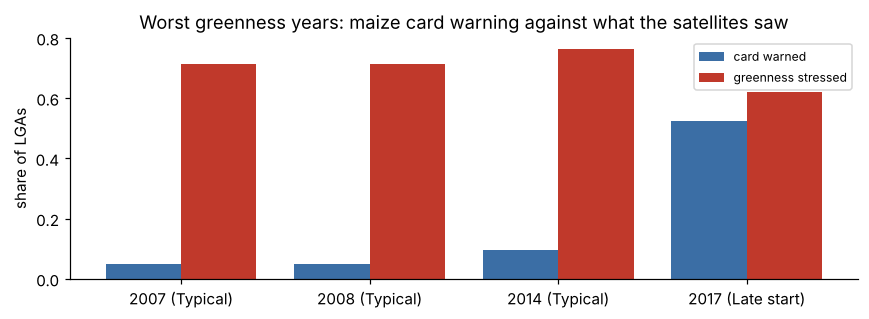

In [7]:
# The four worst statewide greenness years (A5's record): what type each LGA had, how often the
# maize card warned, how often maize failed to fit, and how often greenness was stressed.
yearly = maize.groupby("year")["stressed"].mean()
worst = pd.read_csv(out / "a5" / "a5_year_summary.csv").nsmallest(4, "mean_ndvi_z")["year"].tolist()
bad_years = pd.DataFrame(
    [
        {
            "year": y,
            "main_type": g["season_type"].mode().iloc[0],
            "lgas": len(g),
            "card_warned_share": g["warned_type"].mean(),
            "maize_failed_share": g["failed"].mean(),
            "greenness_stressed_share": g["stressed"].mean(),
            "passes": bool(g["warned_type"].mean() >= 0.5),
        }
        for y, g in maize[maize["year"].isin(worst)].groupby("year")
    ]
)
fig, ax = plt.subplots(figsize=(8, 3))
x = range(len(bad_years))
ax.bar(
    [i - 0.2 for i in x], bad_years["card_warned_share"], 0.4, label="card warned", color="#3b6ea5"
)
ax.bar(
    [i + 0.2 for i in x],
    bad_years["greenness_stressed_share"],
    0.4,
    label="greenness stressed",
    color="#c0392b",
)
ax.set_xticks(list(x), bad_years["year"].astype(str) + " (" + bad_years["main_type"] + ")")
ax.set_ylabel("share of LGAs")
ax.set_title("Worst greenness years: maize card warning against what the satellites saw")
ax.legend(fontsize=8)
plt.tight_layout()
bad_years.round(2)

**Reading.** The PRD's pass condition (Current continuous maize shows higher risk in a bad year) holds for 2017, a late-start year, and fails for 2007, 2008 and 2014. Those were mostly typical-weather years in which maize finished inside the rains, yet greenness fell in about three quarters of LGAs. The tool can warn about season length and water; it cannot see whatever else drove those years (pests, prices, planted area, cloud in the composites). This is said on Learn, and the PRD's open question (a bad season documented in official records) stays open.

## 5. Save and log

In [8]:
# Save the per LGA-year table, the rates and the bad-year check, and log one row per outcome.
a16 = cfg.paths.output_dir / "a16"
rates_all = pd.concat([fit_rates, stress_rates], ignore_index=True)
write_csv(table.drop(columns=["fits"]), a16 / "a16_lga_year_crop.csv")
write_csv(rates_all, a16 / "a16_hit_rates.csv")
write_csv(bad_years, a16 / "a16_bad_years.csv")
maize_fit = fit_rates[fit_rates["crop"] == "maize"].set_index("warning")
summary = {
    "maize_fit_with_type": maize_fit.loc["season type"].drop(["outcome", "crop"]).to_dict(),
    "maize_fit_without_type": maize_fit.loc["no season type"].drop(["outcome", "crop"]).to_dict(),
    "maize_stress_with_type": stress_rates.iloc[0].drop(["outcome", "crop", "warning"]).to_dict(),
    "bad_years_passed": int(bad_years["passes"].sum()),
    "bad_years_tested": len(bad_years),
}
write_json(summary, a16 / "a16_summary.json")
log_experiments(
    cfg.paths.experiment_log,
    [
        experiments.component_row(
            f"A16 backtest: {name}",
            "card warning: leave-one-year-out fit share of the year's season type (A9, A5)",
            "leave-one-year-out, 23 LGAs, 2000-2024",
            {k: round(float(v), 3) for k, v in summary[key].items()},
            "baseline: same warning without the season type",
            experiments.today(),
        )
        for name, key in (
            ("maize season fit", "maize_fit_with_type"),
            ("maize greenness stress", "maize_stress_with_type"),
        )
    ],
)
summary

{'maize_fit_with_type': {'lga_years': 575,
  'bad_years': 97,
  'hit_rate': 0.845360824742268,
  'false_alarm_rate': 0.100418410041841,
  'bad_share_if_warned': 0.6307692307692307,
  'bad_share_if_not_warned': 0.033707865168539325,
  'lift': 18.712820512820514},
 'maize_fit_without_type': {'lga_years': 575,
  'bad_years': 97,
  'hit_rate': 0.8144329896907216,
  'false_alarm_rate': 0.29497907949790797,
  'bad_share_if_warned': 0.35909090909090907,
  'bad_share_if_not_warned': 0.05070422535211268,
  'lift': 7.082070707070707},
 'maize_stress_with_type': {'lga_years': 525,
  'bad_years': 152,
  'hit_rate': 0.21710526315789475,
  'false_alarm_rate': 0.23324396782841822,
  'bad_share_if_warned': 0.275,
  'bad_share_if_not_warned': 0.2938271604938272,
  'lift': 0.9359243697478992},
 'bad_years_passed': 1,
 'bad_years_tested': 4}